# 05 - HLS 30 m (Landsat + Sentinel-2) vs MODIS: coverage, sanity checks and results

This notebook re-draws the key checks and tables of `reports/phase8_results.md` from saved outputs: `data/processed/hls_state.parquet` (+ `_presample`), `modis_state.parquet`, `features_daily.parquet` and `reports/*.csv`. It does not ingest or refit anything. Reproduce with `uv run python scripts/build_hls.py --combine-only`, `scripts/run_state_panel.py`, `scripts/hls_lag_sensitivity.py` and `scripts/run_backtest.py`.

**Group H** (pre-registered, mirrors S): `hls_ndvi_z`, `hls_evi_anom_cum`, `hls_ndvi_trend_anom`, from causal 16-day HLS composites ending every 4 days (May 16 - Sep 29), usable on end date + 7 days. 360 fixed 7.68 km sample blocks (8 MGRS tiles x 9 blocks per state, chosen from CDL 2008-2012), rotation-predicted corn mask per season from CDL Y-1..Y-3.

In [1]:
import glob

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cornsat import panel as P
from cornsat.config import DATA_INTERIM, DATA_PROCESSED, ROOT

REPORTS = ROOT / "reports"
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, GREEN, ORANGE, GREY = "#2a78d6", "#1baf7a", "#eb6834", "#8a8984"  # S, H, C, W+C
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "text.color": INK, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "lines.linewidth": 1.6, "figure.dpi": 80,
})
pd.set_option("display.width", 160)

hls = pd.read_parquet(DATA_PROCESSED / "hls_state.parquet")
pre = pd.read_parquet(DATA_PROCESSED / "hls_state_presample.parquet")
modis = pd.read_parquet(DATA_PROCESSED / "modis_state.parquet")
modis["end_date"] = pd.to_datetime(modis["end_date"]).astype("datetime64[ns]")
print("hls_state", hls.shape, "| presample", pre.shape, "| modis_state", modis.shape)
hls.head(3).T

hls_state (1925, 18) | presample (525, 18) | modis_state (2442, 17)


,0,1,2
state,IA,IA,IA
year,2016,2016,2016
platform,hls,hls,hls
start_date,2016-05-01 00:00:00,2016-05-05 00:00:00,2016-05-09 00:00:00
end_date,2016-05-16 00:00:00,2016-05-20 00:00:00,2016-05-24 00:00:00
mid_date,2016-05-08 00:00:00,2016-05-12 00:00:00,2016-05-16 00:00:00
obs_date,2016-05-05 00:00:00,2016-05-08 00:00:00,2016-05-18 00:00:00
available_date,2016-05-23 00:00:00,2016-05-27 00:00:00,2016-05-31 00:00:00
ndvi_mean,0.243569,0.242454,0.260018
evi_mean,0.145248,0.146589,0.163242


## Coverage by season

One row per (state, composite end date): 35 composites x 5 states per season. `ge05` counts composites that pass the `valid_frac >= 0.5` gate used by the features (clear share of masked pixels). 2013-2015 are the Landsat-only pre-sample, used only for climatology. 2016-17 are thin (Sentinel-2B launched in 2017), and the pre-sample is thinner still, so Indiana lacks 3 usable climatology seasons until 2018.

In [2]:
sc = pd.concat([pd.read_parquet(f) for f in glob.glob(str(DATA_INTERIM / "hls" / "scenes" / "*" / "*.parquet"))])
gr = sc.groupby("granule_id").agg(read=("refl_read", "max"), season=("season", "first"), sensor=("sensor", "first"))
both = pd.concat([pre, hls])
cov = pd.DataFrame({
    "granules_after_prefilter": gr.groupby("season").size(),
    "read_L30": gr[gr["read"]].groupby("season")["sensor"].apply(lambda s: (s == "L30").sum()),
    "read_S30": gr[gr["read"]].groupby("season")["sensor"].apply(lambda s: (s == "S30").sum()),
    "fmask_only": gr[~gr["read"]].groupby("season").size(),
    "composites": both.groupby("year").size(),
    "ge05": both[both["valid_frac"] >= 0.5].groupby("year").size(),
    "mean_valid_frac": both.groupby("year")["valid_frac"].mean().round(2),
    "mean_blocks": both.groupby("year")["n_blocks"].mean().round(1),
})
cov

,granules_after_prefilter,read_L30,read_S30,fmask_only,composites,ge05,mean_valid_frac,mean_blocks
2013,595,386,0,209,175,73,0.44,31.4
2014,617,417,0,200,175,76,0.47,32.5
2015,546,338,0,208,175,69,0.41,28.7
2016,1042,400,291,351,175,127,0.63,45.3
2017,1252,399,408,445,175,143,0.70,50.6
2018,2125,379,1006,740,175,164,0.85,61.2
2019,2145,386,1062,697,175,172,0.88,62.9
2020,2286,369,1078,839,175,159,0.85,61.2
2021,2425,394,1026,1005,175,157,0.81,58.7
2022,2857,764,1190,903,175,175,0.94,67.9


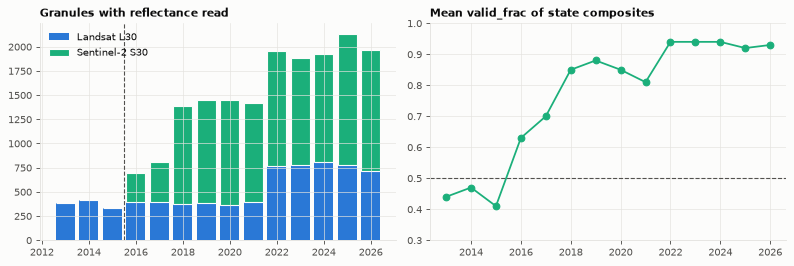

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = cov.index.to_numpy()
axes[0].bar(x, cov["read_L30"], color=BLUE, label="Landsat L30")
axes[0].bar(x, cov["read_S30"], bottom=cov["read_L30"], color=GREEN, label="Sentinel-2 S30", edgecolor=SURF)
axes[0].axvline(2015.5, color=INK2, lw=1, ls="--")
axes[0].set_title("Granules with reflectance read", loc="left"); axes[0].legend(loc="upper left")
axes[1].plot(x, cov["mean_valid_frac"], color=GREEN, marker="o")
axes[1].axhline(0.5, color=INK2, lw=1, ls="--")
axes[1].set_title("Mean valid_frac of state composites", loc="left"); axes[1].set_ylim(0.3, 1)
fig.tight_layout()

In [4]:
# state-seasons with an HLS z-score (days of the as-of panel with hls_ndvi_z), 2016+
fd = pd.read_parquet(DATA_PROCESSED / "features_daily.parquet")
st = fd[(fd["geo"] != "US") & (fd["season"] >= 2016)]
st.groupby(["season", "geo"])["hls_ndvi_z"].apply(lambda s: int(s.notna().sum())).unstack()

geo,IA,IL,IN,MN,NE
season,,,,,
2016,68,115,0,83,91
2017,83,139,0,103,99
2018,135,132,112,150,135
2019,151,143,120,151,143
2020,135,136,116,139,120
2021,147,142,123,138,147
2022,151,151,151,136,151
2023,147,147,151,143,147
2024,151,151,151,151,151


## Sanity checks: HLS vs MODIS

Each HLS composite is matched to the nearest MODIS composite end date (Terra and Aqua averaged) within 4 days. 2025 MODIS stops on Jul 11, so those HLS dates have no partner.

In [5]:
mm = (modis.groupby(["state", "end_date"], as_index=False)["ndvi_mean"].mean()
      .rename(columns={"ndvi_mean": "modis", "end_date": "mend"}).sort_values("mend"))
j = pd.concat([pd.merge_asof(g.sort_values("end_date"), mm[mm["state"] == s].drop(columns="state"),
                             left_on="end_date", right_on="mend", direction="nearest",
                             tolerance=pd.Timedelta(days=4)) for s, g in hls.groupby("state")])
j = j.dropna(subset=["modis", "ndvi_mean"])
r = np.corrcoef(j["ndvi_mean"], j["modis"])[0, 1]
peaks = j.groupby(["state", "year"])[["ndvi_mean", "modis"]].max().mean()
g5 = hls[hls["valid_frac"] >= 0.5]
pk = g5.loc[g5.groupby(["state", "year"])["ndvi_mean"].idxmax()]
print(f"matched composites n={len(j)}, Pearson r={r:.3f}, mean HLS-MODIS={(j['ndvi_mean'] - j['modis']).mean():+.3f}")
print(f"mean seasonal peak over matched dates: HLS {peaks['ndvi_mean']:.3f}, MODIS {peaks['modis']:.3f}")
print(f"HLS peak composite (valid_frac>=0.5): median end-date DOY {pk['end_date'].dt.day_of_year.median():.0f}, "
      f"median obs-date DOY {pk['obs_date'].dt.day_of_year.median():.0f}")
j.groupby("year").apply(lambda g: pd.Series({"n": len(g), "r": np.corrcoef(g["ndvi_mean"], g["modis"])[0, 1],
                                             "mean_diff": (g["ndvi_mean"] - g["modis"]).mean()})).round(3)

matched composites n=1820, Pearson r=0.968, mean HLS-MODIS=-0.007
mean seasonal peak over matched dates: HLS 0.886, MODIS 0.862
HLS peak composite (valid_frac>=0.5): median end-date DOY 216, median obs-date DOY 208


,n,r,mean_diff
year,,,
2016,175.0,0.962,-0.020
2017,175.0,0.971,-0.003
2018,175.0,0.955,-0.009
2019,175.0,0.974,-0.004
2020,175.0,0.971,-0.004
2021,175.0,0.966,-0.004
2022,175.0,0.972,0.000
2023,175.0,0.971,-0.000
2024,165.0,0.971,-0.014


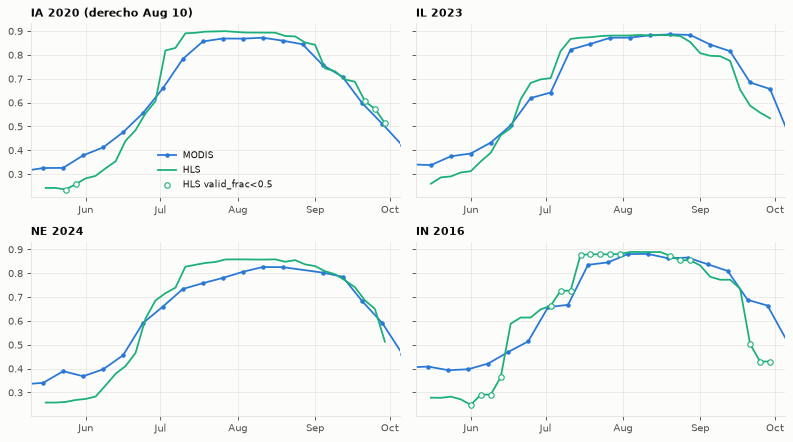

In [6]:
cases = [("IA", 2020, "IA 2020 (derecho Aug 10)"), ("IL", 2023, "IL 2023"), ("NE", 2024, "NE 2024"), ("IN", 2016, "IN 2016")]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6), sharey=True)
for ax, (s, y, t) in zip(axes.flat, cases):
    hh = hls[(hls["state"] == s) & (hls["year"] == y)].sort_values("end_date")
    mo = modis[(modis["state"] == s) & (modis["year"] == y) & modis["end_date"].dt.month.between(5, 10)]
    mo = mo.groupby("end_date", as_index=False)["ndvi_mean"].mean()
    ax.plot(mo["end_date"], mo["ndvi_mean"], color=BLUE, marker="o", ms=3, label="MODIS")
    ax.plot(hh["end_date"], hh["ndvi_mean"], color=GREEN, label="HLS")
    lo = hh[hh["valid_frac"] < 0.5]
    ax.scatter(lo["end_date"], lo["ndvi_mean"], s=24, facecolor=SURF, edgecolor=GREEN, zorder=3, label="HLS valid_frac<0.5")
    ax.set_title(t, loc="left"); ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(pd.Timestamp(y, 5, 10), pd.Timestamp(y, 10, 5))
axes[0, 0].legend(loc="lower center", fontsize=8)
fig.tight_layout()

## State panel (primary test)

Pooled ridge over 5 states, target = state final yield minus the state's own OLS trend (1990..Y-1); season is the unit of validation and inference. All sets of a window are fit and scored on the identical (state, season, snapshot) rows. `ALL` pools the 6 snapshots Jul 1 - Sep 15. Paired tests: d = se(A) - se(B) averaged per season (> 0: B better).

In [7]:
acc = pd.read_csv(REPORTS / "state_panel_accuracy.csv")
pairs = pd.read_csv(REPORTS / "state_panel_paired.csv")
a = acc[(acc["window"] != "2009+") & (acc["snapshot"] == "ALL")]
a.pivot_table(index=["window", "scheme"], columns="set", values="rmse")[["trend", "W+C", "W+C+S", "W+C+H", "S", "H", "usda"]].round(2)

set            trend    W+C  W+C+S  W+C+H      S      H  usda
window scheme                                                
2016+  loso    11.77  11.38  10.86  11.00  10.99  10.99  8.44
       wf      11.20  11.57  11.27  11.38  10.61  11.04  8.34
2019+  loso    11.20  10.61  10.30  10.42  10.49  10.12  8.34
       wf      11.64  11.44  10.79  11.24  10.75  11.01  7.33
2022+  loso    11.00  12.29  15.18  11.27  13.06  14.73   NaN

In [8]:
keep = [("W+C", "W+C+S"), ("W+C", "W+C+H"), ("W+C+S", "W+C+H"), ("S", "H")]
pp = pairs[(pairs["window"] != "2009+") & (pairs["snapshot"] == "ALL")
           & pairs[["A", "B"]].apply(tuple, axis=1).isin(keep)]
pp[["window", "scheme", "A", "B", "n_seasons", "rmse_A", "rmse_B", "n_seasons_B_better", "p_ttest", "p_wilcoxon", "boot_lo", "boot_hi"]].round(3)

,window,scheme,A,B,n_seasons,rmse_A,rmse_B,n_seasons_B_better,p_ttest,p_wilcoxon,boot_lo,boot_hi
98,2016+,loso,S,H,10,10.987,10.987,7,0.848,0.770,-15.443,20.267
119,2016+,loso,W+C,W+C+H,10,11.379,10.996,9,0.096,0.037,1.839,22.805
126,2016+,loso,W+C,W+C+S,10,11.379,10.863,8,0.099,0.105,-0.181,20.207
133,2016+,loso,W+C+S,W+C+H,10,10.863,10.996,5,0.940,0.770,-14.782,19.979
172,2016+,wf,S,H,7,10.606,11.040,3,0.420,0.688,-27.596,7.034
193,2016+,wf,W+C,W+C+H,7,11.566,11.377,5,0.328,0.375,-2.499,10.421
200,2016+,wf,W+C,W+C+S,7,11.566,11.266,5,0.465,0.469,-8.746,20.067
207,2016+,wf,W+C+S,W+C+H,7,11.266,11.377,3,0.783,0.688,-16.196,14.167
246,2019+,loso,S,H,7,10.491,10.122,6,0.397,0.219,-7.742,19.384
267,2019+,loso,W+C,W+C+H,7,10.610,10.422,4,0.448,0.469,-4.572,11.058


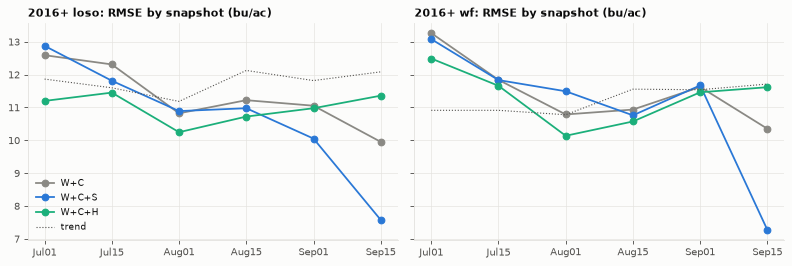

In [9]:
snaps = ["Jul01", "Jul15", "Aug01", "Aug15", "Sep01", "Sep15"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, sch in zip(axes, ["loso", "wf"]):
    s = acc[(acc["window"] == "2016+") & (acc["scheme"] == sch)].set_index(["set", "snapshot"])["rmse"]
    for name, col in [("W+C", GREY), ("W+C+S", BLUE), ("W+C+H", GREEN)]:
        ax.plot(snaps, [s[(name, k)] for k in snaps], color=col, marker="o", label=name)
    ax.plot(snaps, [s[("trend", k)] for k in snaps], color=INK2, ls=":", lw=1, label="trend")
    ax.set_title(f"2016+ {sch}: RMSE by snapshot (bu/ac)", loc="left")
axes[0].legend(fontsize=8)
fig.tight_layout()

## Event timing and lag sensitivity

Event timing: first day each signal's z (standardised against the same prior seasons 2016..Y-1 for every group) crosses -1 after the event. Lag sensitivity: the H block rebuilt in memory with availability = end date + 3, 7 (main), 10, 14 days.

In [10]:
ev = pd.read_csv(REPORTS / "state_panel_events.csv")
ev[["state", "season", "group", "feature", "prior_seasons", "first_cross", "min_z", "min_z_date", "first_cross_after_event", "days_after_event"]].round(2)

,state,season,group,feature,prior_seasons,first_cross,min_z,min_z_date,first_cross_after_event,days_after_event
0,IA,2020,S,ndvi_z,2016-2019,2020-06-06,-4.44,2020-09-26,2020-09-03,24.0
1,IA,2020,S,evi_anom_cum,2016-2019,2020-10-05,-2.73,2020-10-29,2020-10-05,56.0
2,IA,2020,S,ndvi_trend_anom,2016-2019,2020-09-03,-4.70,2020-09-26,2020-09-03,24.0
3,IA,2020,C,ge,2016-2019,2020-08-18,-3.06,2020-10-31,2020-08-18,8.0
4,IA,2020,C,ge_chg_2w,2016-2019,2020-06-16,-19.06,2020-08-29,NaN,NaN
5,IA,2020,H,hls_ndvi_z,2016-2019,2020-09-04,-3.00,2020-09-12,2020-09-04,25.0
6,IA,2020,H,hls_evi_anom_cum,2016-2019,2020-10-02,-1.19,2020-10-06,2020-10-02,53.0
7,IA,2020,H,hls_ndvi_trend_anom,2016-2019,2020-09-04,-5.52,2020-09-12,2020-09-04,25.0
8,IA,2023,S,ndvi_z,2016-2022,2023-06-01,-1.89,2023-06-22,NaN,NaN
9,IA,2023,S,evi_anom_cum,2016-2022,NaN,-0.68,2023-10-29,NaN,NaN


In [11]:
lag = pd.read_csv(REPORTS / "hls_lag_sensitivity.csv")
lag[(lag["A"] == "W+C") & (lag["B"] == "W+C+H")][["hls_lag_days", "window", "scheme", "n_seasons", "rmse_W+C", "rmse_W+C+S", "rmse_W+C+H", "n_seasons_B_better", "p_ttest", "p_wilcoxon"]].round(3)

,hls_lag_days,window,scheme,n_seasons,rmse_W+C,rmse_W+C+S,rmse_W+C+H,n_seasons_B_better,p_ttest,p_wilcoxon
0,3,2016+,loso,10,11.371,10.837,10.666,9,0.021,0.020
1,7,2016+,loso,10,11.379,10.863,10.996,9,0.096,0.037
2,10,2016+,loso,10,11.455,10.984,11.010,9,0.040,0.010
3,14,2016+,loso,10,11.355,10.577,10.991,7,0.509,0.193
12,3,2016+,wf,7,11.397,11.205,10.958,5,0.228,0.375
13,7,2016+,wf,7,11.566,11.266,11.377,5,0.328,0.375
14,10,2016+,wf,7,11.485,11.189,11.266,4,0.271,0.469
15,14,2016+,wf,7,12.021,10.812,11.122,6,0.120,0.156
24,3,2019+,loso,7,10.697,10.318,10.434,4,0.421,0.578
25,7,2019+,loso,7,10.610,10.298,10.422,4,0.448,0.469


## National Stage A and Stage B

National walk-forward H predictions only exist from 2021 (n = 5 scored seasons), so the national test is underpowered. The three-way table scores W+C, W+C+S and W+C+H on the same (season, snapshot) cells. Stage B compares strategies on the seasons where H trades (2021-2026).

In [12]:
tw = pd.read_csv(REPORTS / "stageA_threeway.csv")
tw[(tw["base"] == "W+C") & (tw["with_s"] == "W+C+H")][["scheme", "snapshot", "n", "seasons", "rmse_W+C", "rmse_W+C+S", "rmse_W+C+H"]].round(2)

,scheme,snapshot,n,seasons,rmse_W+C,rmse_W+C+S,rmse_W+C+H
0,wf,Jun15,4,2022-2025,3.54,3.48,4.10
1,wf,Jul01,5,2021-2025,9.32,9.75,4.47
2,wf,Jul15,5,2021-2025,3.41,2.33,5.00
3,wf,Aug01,5,2021-2025,3.36,2.62,7.81
4,wf,Aug15,4,2021-2024,2.68,3.97,7.43
5,wf,Sep01,4,2021-2024,2.85,2.01,2.27
6,wf,Sep15,4,2021-2024,3.87,1.55,5.47
7,wf,ALL,5,2021-2025,4.68,4.53,5.69
24,loso,Jun15,10,2016-2025,5.53,5.65,5.56
25,loso,Jul01,10,2016-2025,7.61,7.99,4.72


In [13]:
sh = pd.read_csv(REPORTS / "stageB_sat_shared.csv").set_index("signal")
sh[["seasons", "pnl_W+C", "pnl_W+C+S", "pnl_W+C+H", "pnl_S", "pnl_H", "diff_WCH_minus_WCS", "diff_lo", "diff_hi", "seasons_H_better", "seasons_S_better"]]

,seasons,pnl_W+C,pnl_W+C+S,pnl_W+C+H,pnl_S,pnl_H,diff_WCH_minus_WCS,diff_lo,diff_hi,seasons_H_better,seasons_S_better
signal,,,,,,,,,,,
level,"2021,2022,2023,2024,2025,2026",-5075.0,-1682.5,-14377.5,-147.5,-1622.5,-12695.0,-20707.5000,-6625.0,0,6
change,"2021,2022,2023,2024,2025,2026",-10997.5,-687.5,-3882.5,-1585.0,4075.0,-3195.0,-12855.0000,6465.0,2,4
vs_usda,"2021,2022,2023,2024,2025,2026",4730.0,3582.5,-1735.0,-3052.5,-845.0,-5317.5,-20048.4375,5092.5,3,2


In [14]:
summ = pd.read_csv(REPORTS / "stageB_summary.csv").set_index("strategy")
rows = ["always_short", "vs_usda|C", "change|H", "change|W+C+S", "level|W+C+S", "vs_usda|W+C+S",
        "level|H", "vs_usda|H", "vs_usda|W+C+H", "change|W+C+H", "level|W+C+H"]
summ.loc[rows, ["net_pnl", "sharpe", "seasons_pos", "trades", "pnl_lo", "pnl_hi", "p_random_full"]].round(2)

,net_pnl,sharpe,seasons_pos,trades,pnl_lo,pnl_hi,p_random_full
strategy,,,,,,,
always_short,24035.0,0.93,10,26,7885.00,40873.12,0.02
vs_usda|C,4190.0,0.35,7,40,-6355.06,16047.62,0.27
change|H,4075.0,0.33,4,52,-2075.00,10752.56,0.27
change|W+C+S,1892.5,0.10,6,123,-7487.81,12117.56,0.33
level|W+C+S,-2577.5,-0.17,7,90,-26084.12,17775.25,0.47
vs_usda|W+C+S,-400.0,-0.18,5,36,-11577.62,13302.81,0.40
level|H,-1622.5,-0.17,1,32,-5795.00,3102.50,0.44
vs_usda|H,-845.0,-0.02,2,18,-5097.56,3205.00,0.42
vs_usda|W+C+H,-5715.0,-0.51,4,43,-12720.12,455.25,0.57


## Verdict

HLS 30 m tracks MODIS closely (r = 0.97 on matched composites) and is a valid, sharper measurement of the same thing. As a yield or price signal it adds at most a small, fragile gain over weather + crop condition in the state panel (2016+ leave-one-season-out only; gone with walk-forward, after 2019, and with a 14-day availability lag), no gain over MODIS, and nothing tradable. See `reports/phase8_results.md`.